# 02 · Cleaning decisions & feature engineering

Notebook 01 did the *structural* clean-up in SQL (duplicates, empty rows, placeholder zeros, flags). Here we make the *statistical* decisions:

| Question | Decision (justified below) |
|---|---|
| Which pollutants can we model? | drop **Xylene** (61 % missing); keep 11 |
| How to treat missing pollutant values? | forward-fill gaps ≤ 3 days **within a city** (causal); rest imputed *inside the model pipeline*, fitted on train only |
| Do we impute the target (AQI)? | **never** |
| Which rows can be used for modelling? | AQI known + ≥ 1 PM value + ≥ 3 pollutants (CPCB's own completeness rule); suspect city excluded |
| Imputer for linear models? | median (MICE tested: no accuracy gain, less robust) |
| How to split? | chronological: train < 2019-01-01 ≤ test |

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, BayesianRidge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from src import db, config, features, cpcb, modeling, evaluate
from src.config import POLLUTANTS, MODEL_POLLUTANTS, LABELS, TEST_START
from src.viz import set_style, save_fig
set_style()
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

conn = db.get_conn()
fact = db.read_fact(conn)               # cleaned fact table joined with city names (SQL view)
print(fact.shape); fact.head()

(28157, 21)


,city,state,region,city_id,date,pm25,pm10,no_,no2,nox,nh3,co,so2,o3,benzene,toluene,xylene,aqi,aqi_bucket,is_outlier,is_suspect
0,Ahmedabad,Gujarat,West,1,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,NaN,0.02,NaN,NaN,NaN,0,1
1,Ahmedabad,Gujarat,West,1,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN,0,1
2,Ahmedabad,Gujarat,West,1,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN,0,1
3,Ahmedabad,Gujarat,West,1,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN,0,1
4,Ahmedabad,Gujarat,West,1,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN,0,1


## 1 · Missing values – where, how much, and since when?

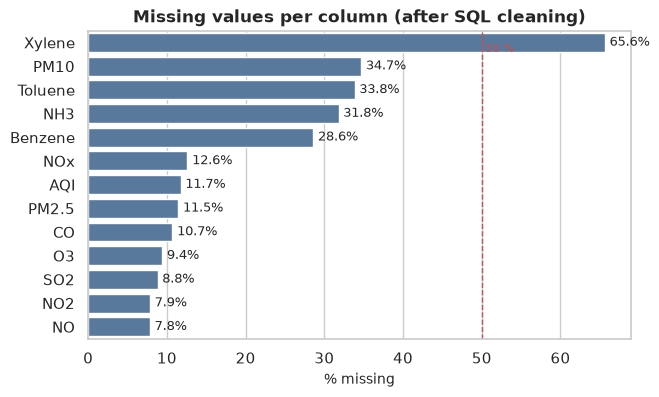

In [2]:
miss = fact[POLLUTANTS + ["aqi"]].isna().mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=miss.values, y=[LABELS[c] for c in miss.index], color="#4c78a8", ax=ax)
for i, v in enumerate(miss.values): ax.text(v + 0.6, i, f"{v:.1f}%", va="center", fontsize=9)
ax.axvline(50, color="r", ls="--", lw=1); ax.text(50.5, 0.4, "50 %", color="r", fontsize=8)
ax.set_xlabel("% missing"); ax.set_title("Missing values per column (after SQL cleaning)")
save_fig("02_missing_by_column"); plt.show()

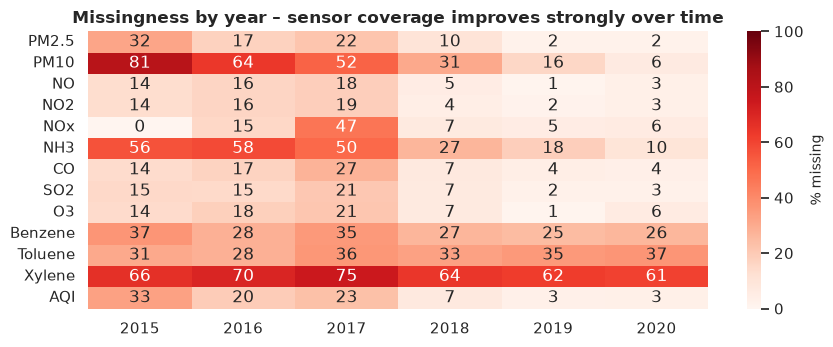

In [3]:
by_year = fact.groupby(fact["date"].dt.year)[POLLUTANTS + ["aqi"]].agg(lambda s: s.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(by_year.T.rename(index=LABELS), annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missingness by year – sensor coverage improves strongly over time"); ax.set_xlabel("")
save_fig("02_missing_by_year"); plt.show()

**Reading:** Xylene (≈ 61 %) is dropped from modelling. PM10 was ~80 % missing in 2015 and ~8 % in 2020, so *old* rows are much poorer than *new* rows – another reason to split by time and to expect the 2019-20 test period to be the cleanest.

Lucknow reports **no PM10 at all**, and Gurugram has only about half of it – the model must cope with whole columns missing for some cities (see check below).

In [4]:
pm10_cov = fact.groupby("city")["pm10"].apply(lambda s: s.notna().mean() * 100).round(0).sort_values()
print("Cities with <20 % PM10 coverage:", pm10_cov[pm10_cov < 20].to_dict())

Cities with <20 % PM10 coverage: {'Lucknow': 0.0, 'Patna': 11.0, 'Chennai': 15.0}


## 2 · How long are the gaps? → choosing the forward-fill limit

We rebuild a gap-free daily calendar per city and measure the length of consecutive missing runs for PM2.5.

275 missing runs for PM2.5; median length 2 days
share of runs that are <=1 day: 44%, <=3 days: 69%, <=7 days: 81%


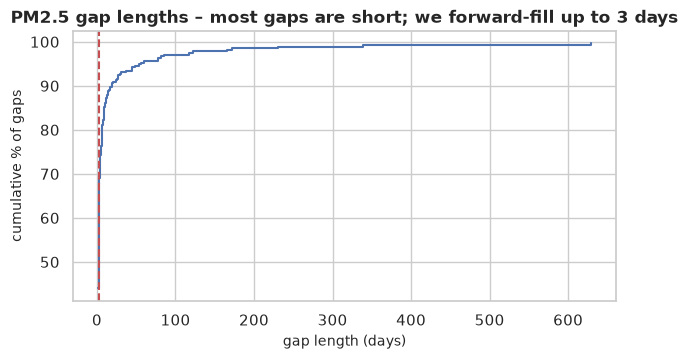

In [5]:
dense = features.densify(fact)
def run_lengths(s):
    isn = s.isna()
    grp = (isn != isn.shift()).cumsum()
    return isn.groupby(grp).sum()[isn.groupby(grp).first()]
runs = pd.concat([run_lengths(g["pm25"]) for _, g in dense.groupby("city")])
cum = runs.value_counts().sort_index().cumsum() / len(runs) * 100
print(f"{len(runs)} missing runs for PM2.5; median length {runs.median():.0f} days")
print("share of runs that are <=1 day: %.0f%%, <=3 days: %.0f%%, <=7 days: %.0f%%" % tuple(cum.reindex([1, 3, 7]).values))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(cum.index[:40], cum.values[:40], where="post"); ax.axvline(3, color="r", ls="--"); ax.set_xlabel("gap length (days)")
ax.set_ylabel("cumulative % of gaps"); ax.set_title("PM2.5 gap lengths – most gaps are short; we forward-fill up to 3 days")
save_fig("02_gap_lengths"); plt.show()

Short gaps are sensor hiccups – carrying the last value forward (**causal**, no future information) for ≤ 3 days is reasonable. Long gaps are structural (station offline) and must not be invented.

## 3 · Imputation experiment – median vs MICE (documented decision)

The sophisticated option (MICE / `IterativeImputer`) is not automatically better. We compare imputers for a Linear Regression with **5-fold expanding-window time-series CV, using the training period (before 2019) only** – the test period is never touched when making this choice.

In [6]:
from sklearn.model_selection import TimeSeriesSplit
work = features.build_feature_table(fact)
pop = work[(work.valid_same_day == 1) & (work.is_suspect == 0)]
tr_all = pop[pop.date < TEST_START].sort_values("date")
num = MODEL_POLLUTANTS + features.CALENDAR_FEATURES + features.EVENT_FEATURES; cat = features.CATEGORICAL_FEATURES

def cv_imputer(imputer):
    rows = []
    for a, b in TimeSeriesSplit(n_splits=5).split(tr_all):
        t, v = tr_all.iloc[a], tr_all.iloc[b]
        prep = ColumnTransformer([("num", Pipeline([("i", imputer), ("s", StandardScaler())]), num),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
        p = Pipeline([("prep", prep), ("m", LinearRegression())]).fit(t[num + cat], t["aqi"])
        pr = p.predict(v[num + cat])
        rows.append(evaluate.regression_metrics(v["aqi"], pr) | {"lowest_prediction": pr.min()})
    return pd.DataFrame(rows).mean()

imp_table = pd.DataFrame({
    "median": cv_imputer(SimpleImputer(strategy="median")),
    "median + missing-indicator": cv_imputer(SimpleImputer(strategy="median", add_indicator=True)),
    "MICE (IterativeImputer + BayesianRidge)": cv_imputer(IterativeImputer(BayesianRidge(), max_iter=5, initial_strategy="median", skip_complete=True, random_state=0)),
}).T.round(2)
imp_table

,MAE,RMSE,R2,lowest_prediction
median,34.62,47.39,0.78,42.42
median + missing-indicator,34.99,48.26,0.77,28.17
MICE (IterativeImputer + BayesianRidge),35.23,46.84,0.78,28.50


**Result:** the imputers are essentially tied in accuracy (R² ≈ 0.78, MAE within ~1 AQI point), but MICE is slower and more complex, and it extrapolates linearly on skewed, outlier-heavy data. **The decision rests on the tie:** when options perform equally on validation we take the simplest, most robust one → **median imputation** (fitted on training data only) for the linear / neural models.
*(Side note, not used for the decision: in an extra check on the later 2019+ period MICE occasionally produced impossible negative AQI predictions, which supports staying with the simpler option.)*
Tree models (Decision Tree, Random Forest, Gradient Boosting) accept missing values natively, so they receive the data without imputation.

## 4 · Feature engineering

`features.build_feature_table()` creates, for every (city, day):

| Group | Columns | Why |
|---|---|---|
| Calendar | `month`, `dayofweek`, `is_weekend`, `season`, `is_winter`, `month_sin/cos` | seasonality (winter inversion, monsoon wash-out); cyclic encoding keeps Dec next to Jan |
| Festival / events | `is_diwali_window` (D-1…D+3), `is_holi_window`, `is_dussehra_window`, `is_stubble_season` (15 Oct–30 Nov), `is_lockdown` (25 Mar–31 May 2020), `days_from_diwali/holi/dussehra` | fireworks, crop-residue burning, COVID natural experiment |
| Lags (next-day task only) | `aqi_lag1/2/3/7`, `aqi_roll3/7`, `aqi_roll7_std`, `pm25_lag1`, `pm10_lag1`, `aqi_change_1d` | persistence of pollution episodes |
| Targets | `aqi` (same-day), `aqi_bucket`, `aqi_next`, `bucket_next` | regression and classification |

`year` is deliberately **not** a feature: with a chronological split a tree cannot extrapolate to unseen years.

In [7]:
print(work.shape)
print("columns:", list(work.columns))
flags = ["is_diwali_window", "is_holi_window", "is_dussehra_window", "is_stubble_season", "is_lockdown", "is_weekend", "is_winter"]
display(work[flags].sum().to_frame("flagged_rows").T)
# sanity check: the festival windows should cover only a few days around the dates in config
chk = work[work.is_diwali_window == 1].groupby(work.date.dt.year)["date"].agg(["min", "max"])
chk

(28157, 55)
columns: ['date', 'city', 'state', 'region', 'city_id', 'pm25', 'pm10', 'no_', 'no2', 'nox', 'nh3', 'co', 'so2', 'o3', 'benzene', 'toluene', 'xylene', 'aqi', 'aqi_bucket', 'is_outlier', 'is_suspect', 'n_ffilled', 'year', 'month', 'day', 'dayofweek', 'dayofyear', 'quarter', 'is_weekend', 'season', 'is_winter', 'month_sin', 'month_cos', 'days_from_diwali', 'is_diwali_window', 'days_from_holi', 'is_holi_window', 'days_from_dussehra', 'is_dussehra_window', 'is_stubble_season', 'is_lockdown', 'aqi_lag1', 'aqi_lag2', 'aqi_lag3', 'aqi_lag7', 'aqi_roll3', 'aqi_roll7', 'aqi_roll7_std', 'pm25_lag1', 'pm10_lag1', 'aqi_change_1d', 'aqi_next', 'bucket_next', 'valid_same_day', 'valid_next_day']


,is_diwali_window,is_holi_window,is_dussehra_window,is_stubble_season,is_lockdown,is_weekend,is_winter
flagged_rows,351,258,207,3322,1736,7972,7158


,min,max
date,,
2015,2015-11-10,2015-11-14
2016,2016-10-29,2016-11-02
2017,2017-10-18,2017-10-22
2018,2018-11-06,2018-11-10
2019,2019-10-26,2019-10-30


In [8]:
# lag features must align with the calendar: check on one city
d = work[work.city == "Delhi"].set_index("date")
assert (d["aqi_lag1"].dropna() == d["aqi"].shift(1).dropna()).all()
assert (d["aqi_next"].dropna() == d["aqi"].shift(-1).dropna()).all()
d.loc["2019-10-25":"2019-10-31", ["aqi", "aqi_lag1", "aqi_next", "bucket_next", "is_diwali_window", "is_stubble_season"]]

,aqi,aqi_lag1,aqi_next,bucket_next,is_diwali_window,is_stubble_season
date,,,,,,
2019-10-25,331.0,335.0,315.0,Very Poor,0,1
2019-10-26,315.0,331.0,354.0,Very Poor,1,1
2019-10-27,354.0,315.0,417.0,Severe,1,1
2019-10-28,417.0,354.0,419.0,Severe,1,1
2019-10-29,419.0,417.0,452.0,Severe,1,1
2019-10-30,452.0,419.0,460.0,Severe,1,1
2019-10-31,460.0,452.0,591.0,Severe,0,1


## 5 · Domain check – can we re-compute the AQI from the pollutants?

India's CPCB defines the daily AQI as the **maximum of the pollutant sub-indices** (needs ≥ 3 pollutants, one of them PM2.5/PM10). `src/cpcb.py` implements the breakpoint formula. This (a) validates the data, (b) tells us which pollutant *drives* the AQI, and (c) explains why same-day regression is easy.

23,500 days:  R² = 0.866   MAE = 22.6   same AQI category = 72.0%


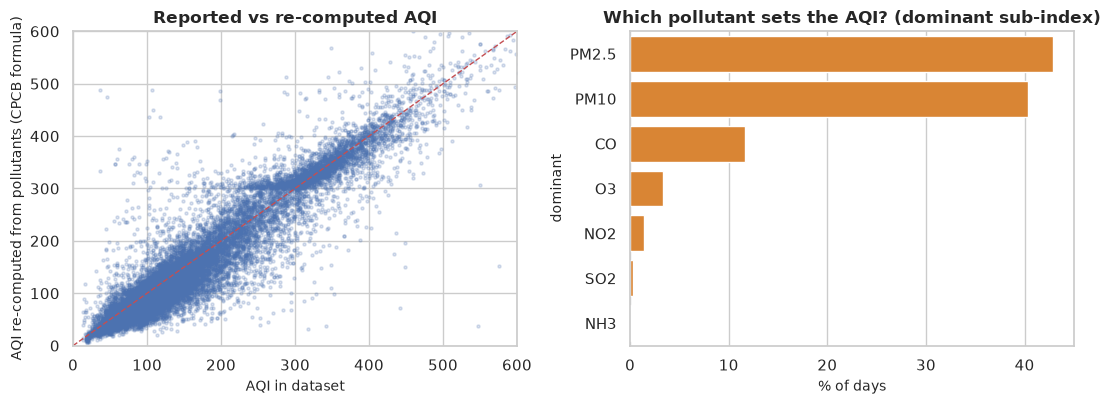

In [9]:
work["aqi_cpcb"], work["dominant"] = cpcb.reconstruct_aqi(work)
ok = work["aqi_cpcb"].notna() & work["aqi"].notna() & (work.is_suspect == 0)
r = evaluate.regression_metrics(work.loc[ok, "aqi"], work.loc[ok, "aqi_cpcb"])
same_bucket = (work.loc[ok, "aqi_cpcb"].map(config.aqi_to_bucket) == work.loc[ok, "aqi_bucket"]).mean()
print(f"{ok.sum():,} days:  R² = {r['R2']:.3f}   MAE = {r['MAE']:.1f}   same AQI category = {same_bucket:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(work.loc[ok, "aqi"], work.loc[ok, "aqi_cpcb"], s=5, alpha=0.2); axes[0].plot([0, 600], [0, 600], "r--", lw=1)
axes[0].set_xlim(0, 600); axes[0].set_ylim(0, 600); axes[0].set_xlabel("AQI in dataset"); axes[0].set_ylabel("AQI re-computed from pollutants (CPCB formula)")
axes[0].set_title("Reported vs re-computed AQI")
dom = work.loc[ok, "dominant"].map(LABELS.get).value_counts(normalize=True).mul(100)
sns.barplot(x=dom.values, y=dom.index, color="#f58518", ax=axes[1]); axes[1].set_xlabel("% of days"); axes[1].set_title("Which pollutant sets the AQI? (dominant sub-index)")
plt.tight_layout(); save_fig("02_cpcb_validation"); plt.show()

The formula reproduces the dataset's AQI quite well (a perfect match is not expected: the dataset uses 24-hour averages for PM and 8-hour maxima for CO/O3, we only have daily values), and confirms that **PM2.5 and PM10 are the dominant pollutants on most days**, with CO a notable third. Consequence: *same-day* AQI regression from the pollutants is a nearly deterministic problem, so high R² there is expected – the genuinely hard task is **next-day** forecasting (notebook 07).

## 6 · Which rows are used for modelling?

In [10]:
work["in_model_pop"] = ((work.valid_same_day == 1) & (work.is_suspect == 0)).astype(int)
summary = pd.Series({
    "rows in fact_aqi (cleaned)": len(work),
    "… with AQI known": int(work.aqi.notna().sum()),
    "… + at least one PM value and ≥3 pollutants (valid_same_day)": int(work.valid_same_day.sum()),
    "… excluding suspect city Ahmedabad (modelling population)": int(work.in_model_pop.sum()),
    "… next-day task (tomorrow's AQI also known)": int(((work.in_model_pop == 1) & (work.valid_next_day == 1)).sum()),
}, name="rows"); summary.to_frame()

,rows
rows in fact_aqi (cleaned),28157
… with AQI known,24850
… + at least one PM value and ≥3 pollutants (valid_same_day),24834
… excluding suspect city Ahmedabad (modelling population),23500
… next-day task (tomorrow's AQI also known),23030


In [11]:
pop = work[work.in_model_pop == 1]
train, test = modeling.time_split(pop, TEST_START)
tbl = pd.DataFrame({"train": train.groupby("city").size(), "test": test.groupby("city").size()}).fillna(0).astype(int)
tbl["total"] = tbl.sum(axis=1); tbl = tbl.sort_values("total", ascending=False)
print(f"train: {len(train):,} rows ({train.date.min():%Y-%m-%d} → {train.date.max():%Y-%m-%d})   test: {len(test):,} rows ({test.date.min():%Y-%m-%d} → {test.date.max():%Y-%m-%d})")
tbl.T

train: 12,541 rows (2015-01-01 → 2018-12-31)   test: 10,959 rows (2019-01-01 → 2020-07-01)


city,Delhi,Bengaluru,Lucknow,Chennai,Hyderabad,Patna,Gurugram,Visakhapatnam,Amritsar,Jaipur,Thiruvananthapuram,Amaravati,Mumbai,Jorapokhar,Kolkata,Brajrajnagar,Talcher,Guwahati,Coimbatore,Chandigarh,Bhopal,Shillong,Kochi,Ernakulam,Aizawl
train,1451,1362,1345,1336,1332,917,906,652,590,546,518,349,227,306,206,270,228,0,0,0,0,0,0,0,0
test,548,548,548,548,548,542,547,519,536,548,534,492,548,465,548,438,459,495,344,299,278,205,158,153,111
total,1999,1910,1893,1884,1880,1459,1453,1171,1126,1094,1052,841,775,771,754,708,687,495,344,299,278,205,158,153,111


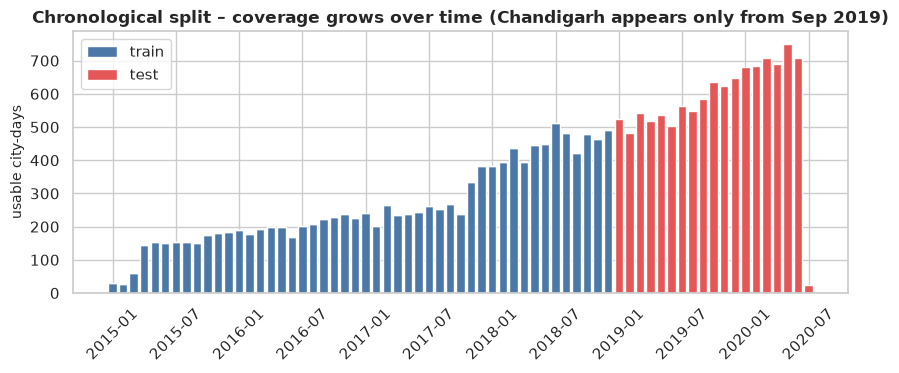

In [12]:
m = pop.groupby([pop.date.dt.to_period("M").dt.to_timestamp(), pop.date >= TEST_START]).size().unstack(fill_value=0)
m.columns = ["train", "test"]
x = np.arange(len(m))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(x, m["train"], color="#4c78a8", label="train"); ax.bar(x, m["test"], bottom=m["train"], color="#e45756", label="test")
ax.set_xticks(x[::6]); ax.set_xticklabels([d.strftime("%Y-%m") for d in m.index[::6]], rotation=45)
ax.set_ylabel("usable city-days"); ax.legend(); ax.set_title("Chronological split – coverage grows over time (Chandigarh appears only from Sep 2019)")
save_fig("02_split_timeline"); plt.show()

**Important for later:** Chandigarh's data starts in Sept 2019, so with a global time split it lives **only in the test set**. That is actually a nice experiment – *"can a model trained on other cities predict a city it has never seen?"* – and is analysed in notebook 07.

## 7 · Save: `aqi_features` table in SQLite + CSV

In [13]:
out = work.copy()
out["date"] = out["date"].dt.strftime("%Y-%m-%d")
out.to_sql("aqi_features", conn, if_exists="replace", index=False)
conn.execute("CREATE INDEX IF NOT EXISTS idx_feat_city_date ON aqi_features(city, date)"); conn.commit()
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
out.to_csv(config.DATA_PROCESSED / "aqi_features.csv", index=False)
imp_table.to_csv(config.RESULTS_DIR / "imputation_experiment.csv")
print(db.query("SELECT COUNT(*) AS rows, SUM(in_model_pop) AS model_rows, MIN(date) AS first, MAX(date) AS last FROM aqi_features", conn))
print("saved:", (config.DATA_PROCESSED / "aqi_features.csv").relative_to(ROOT), f"({(config.DATA_PROCESSED / 'aqi_features.csv').stat().st_size/1e6:.1f} MB)")
conn.close()

    rows  model_rows       first        last
0  28157       23500  2015-01-01  2020-07-01
saved: data/processed/aqi_features.csv (8.9 MB)


### Take-aways
* Missing values: Xylene dropped; ≤ 3-day gaps carried forward per city; remaining gaps handled inside model pipelines (median for linear / NN models, native NaN support for trees). The target is never imputed.
* **MICE was tested and gave no accuracy gain** (and can produce negative AQI), so the simpler median imputer is used.
* 24.8 k valid city-days; 23.5 k after excluding Ahmedabad; chronological split gives ~12.5 k train / ~11 k test rows.
* The CPCB formula re-computation shows PM2.5/PM10 dominate the AQI → same-day regression is easy, next-day is the real challenge.

➡ Next: `03_EDA.ipynb`.